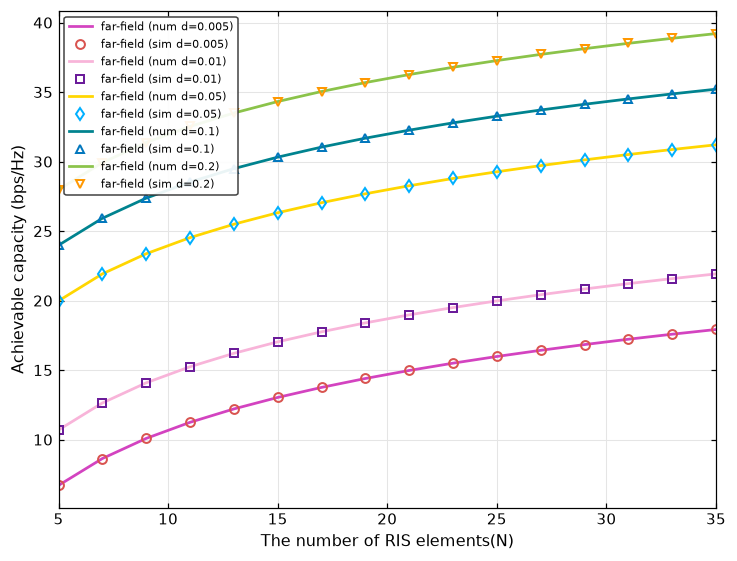

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#tham số paper cho
c = 3e8
f1 = 3e9                       
Pt = 1e-3 * 10 ** (20 / 10)    
d1, d2 = 0.8e3, 5e3            
th_b, ph_b, ph_u = np.pi / 6, np.pi / 3, np.pi / 6   
d_list = [0.005, 0.01, 0.05, 0.1, 0.2]               
N_list = np.arange(5, 36, 2)                         

#paper không nhắc tới
th_u = np.pi / 6               
Gt_dB = Gr_dB = 31.6           

#đại lượng dẫn xuất
lam = c / f1
sigma2 = 2.5e-20   
Gt, Gr = 10 ** (Gt_dB / 10), 10 ** (Gr_dB / 10)
F = lambda th, w=1: np.cos(th) ** w                  # ct (4), omega=1 
Om1 = np.sin(th_b) * np.cos(ph_b)                    
Om2 = np.sin(th_u) * np.cos(ph_u)                   

def path_loss(d):
    """Eq.(5),(6): PL = 4π d_i² / (G F d² Ω)  (đọc từ PDF)"""
    PL1 = 4 * np.pi * d1**2 / (Gt * F(th_b) * d**2 * Om1)
    PL2 = 4 * np.pi * d2**2 / (Gr * F(th_u) * d**2 * Om2)
    return PL1, PL2

# num: ct (11)
def C_analytic(N, d):
    snr = Pt / sigma2 * Gt * Gr * N**4 * d**4 * Om1 * Om2 * F(th_b) * F(th_u) \
          / (16 * np.pi**2 * d1**2 * d2**2)
    return np.log2(1 + snr)

# sim: cộng trực tiếp N*N phần tử với pha tối ưu, CT (9)-(10)
def C_simulated(N, d):
    PL1, PL2 = path_loss(d)
    idx = np.arange(N) - (N - 1) / 2
    m, n = np.meshgrid(idx, idx)                      # lưới phần tử
    h1 = np.exp(-1j * 2*np.pi*f1*d1/c) / np.sqrt(PL1) * np.ones_like(m)
    h2 = np.exp(-1j * 2*np.pi*f1*d2/c) / np.sqrt(PL2) * np.ones_like(m)
    alpha = 2*np.pi*f1*(d1 + d2)/c                    # pha tối ưu
    beta = 1.0
    Theta = beta * np.exp(1j * alpha) * np.ones_like(m)
    h = np.sum(h2 * Theta * h1)                       
    snr = Pt / sigma2 * np.abs(h)**2
    return np.log2(1 + snr)

# kiểm tra FFC: d1 > 2D^2/lambda
#for d in d_list:
 #   Dmax = N_list[-1] * d
 #   R = 2 * Dmax**2 / lam
 #   print(f"d={d:5.3f} m, N=35: Rayleigh={R:8.1f} m  ->  "
 #         f"{'FFC OK' if min(d1, d2) > R else 'KHÔNG còn far-field (d1<=R)'}")

# CẤU HÌNH MÀU SẮC VÀ KÝ HIỆU

plot_configs = [
    {"d": 0.005, "line_color": "#d343c0", "marker": "o", "edge_color": "#d9534f"},  
    {"d": 0.010, "line_color": "#f8b4d9", "marker": "s", "edge_color": "#6a1b9a"},  
    {"d": 0.050, "line_color": "#ffd600", "marker": "d", "edge_color": "#00b0ff"},  
    {"d": 0.100, "line_color": "#00838f", "marker": "^", "edge_color": "#0277bd"},  
    {"d": 0.200, "line_color": "#8bc34a", "marker": "v", "edge_color": "#ff9800"}, 
]

# vẽ đồ thị 
fig, ax = plt.subplots(figsize=(6.8, 5.2), dpi=110)

for cfg in plot_configs:
    d = cfg["d"]
    num = [C_analytic(N, d) for N in N_list]
    sim = [C_simulated(N, d) for N in N_list]
    
    #1. Đường nét liền (num)
    ax.plot(N_list, num, linestyle='-', color=cfg["line_color"], linewidth=1.8, 
            label=f'far-field (num d={d})')
    
    #2. Điểm rời rạc mô phỏng (sim)
    ax.plot(N_list, sim, linestyle='None', marker=cfg["marker"], markersize=5.8, 
            markerfacecolor='none', markeredgecolor=cfg["edge_color"], markeredgewidth=1.3, 
            label=f'far-field (sim d={d})')

#Định dạng nhãn và hiển thị 
ax.set_xlabel('The number of RIS elements(N)', fontsize=10.5)
ax.set_ylabel('Achievable capacity (bps/Hz)', fontsize=10.5)
ax.set_xlim(5, 35)

ax.grid(True, linestyle='-', color='#e5e5e5', linewidth=0.7)
ax.legend(fontsize=7.5, loc='upper left', framealpha=0.92, edgecolor='#333333')
ax.tick_params(direction='in', top=True, right=True, labelsize=9.5)

plt.tight_layout()
plt.show()

#in đối chiếu
#for d in d_list:
 #   print(f"d={d}: C(N=5)={C_analytic(5,d):.2f}, C(N=35)={C_analytic(35,d):.2f}")